# Hello, and welcome to my first attempt at the Titanic Survival Kaggle Competition!
First, let's download and import the Kaggle API we will be using to acquire the datasets, then download the titanic.zip file, extract the files within, and save them as objects; we will be using these throughout the notebook.

Note: For this to function properly, you will have to have a Kaggle API token

In [5]:
try:
    import kaggle
    print('kaggle imported!')
except:
    !pip install kaggle
    import kaggle
    print('kaggle installed and imported!')
import pandas as pd
import zipfile
kaggle.api.authenticate()
kaggle.api.competition_download_files('titanic', quiet = False)
with zipfile.ZipFile('titanic.zip', 'r') as zip_file:
    zip_file.extractall('extracted_files/')
train_data = pd.read_csv('extracted_files/train.csv')
test_data = pd.read_csv('extracted_files/test.csv')

kaggle imported!


100%|██████████| 34.1k/34.1k [00:00<00:00, 16.9MB/s]

In [6]:
train_data.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
test_data.head(5)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [8]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Our training and test datasets look correct, and we can see in our training dataset that we have a mixture of numeric and categorical features. In addition, the Cabin feature is over 80% null values, which may warrant our dropping alltogether. Let's look at that and other potenially problematic features by doing some EDA.

## Effect of Pclass on Survival

In [53]:
#Get counts of surviving and deceased members of each class
surviving_1st = len(train_data[(train_data['Pclass'] == 1) & (train_data['Survived'] == 1)])
surviving_2nd = len(train_data[(train_data['Pclass'] == 2) & (train_data['Survived'] == 1)])
surviving_3rd = len(train_data[(train_data['Pclass'] == 3) & (train_data['Survived'] == 1)])
deceased_1st = len(train_data[(train_data['Pclass'] == 1) & (train_data['Survived'] == 0)])
deceased_2nd = len(train_data[(train_data['Pclass'] == 2) & (train_data['Survived'] == 0)])
deceased_3rd = len(train_data[(train_data['Pclass'] == 3) & (train_data['Survived'] == 0)])

print(f'Surviving 1st: {surviving_1st} | Deceased 1st: {deceased_1st} | Total 1st: {surviving_1st + deceased_1st}')
print(f'Surviving 2nd: {surviving_2nd} | Deceased 2nd: {deceased_2nd} | Total 2nd: {surviving_2nd + deceased_2nd}')
print(f'Surviving 3rd: {surviving_3rd} | Deceased 3rd: {deceased_3rd} | Total 3rd: {surviving_3rd + deceased_3rd}')

Surviving 1st: 136 | Deceased 1st: 80 | Total 1st: 216
Surviving 2nd: 87 | Deceased 2nd: 97 | Total 2nd: 184
Surviving 3rd: 119 | Deceased 3rd: 372 | Total 3rd: 491


In [61]:
#Chi-Squre test on survival by class matrix
import numpy as np
from scipy.stats import chi2_contingency
Pclass_survival_array = np.array([[surviving_1st, surviving_2nd, surviving_3rd],
                                 [deceased_1st, deceased_2nd, deceased_3rd]])
print(pd.DataFrame(Pclass_survival_array, columns = ['1st Class', '2nd Class', '3rd Class'], index = ['Survived', 'Deceased']))
print(f'Chi-Squre P_value: {chi2_contingency(Pclass_survival_array).pvalue}')

          1st Class  2nd Class  3rd Class
Survived        136         87        119
Deceased         80         97        372
Chi-Squre P_value: 4.5492517112987287e-23


Text(0.5, 1.0, 'Survival Rate by Class')

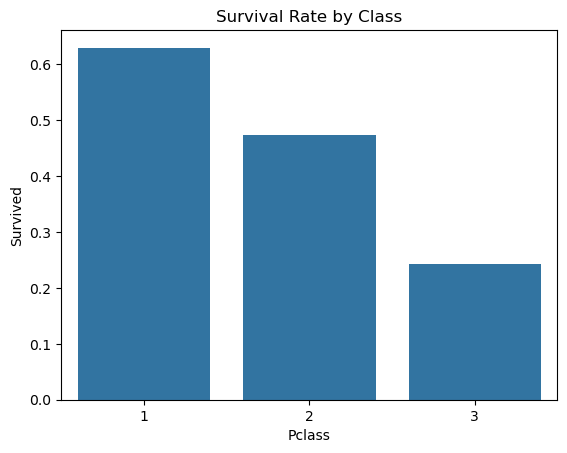

In [65]:
#Visualize survival rates with bargraph
import seaborn as sns
sns.barplot(train_data.groupby('Pclass')['Survived'].mean())
plt.title('Survival Rate by Class')

## Effect of Age on Survival 

Text(0.5, 1.0, 'Ages of Deceased Passengers')

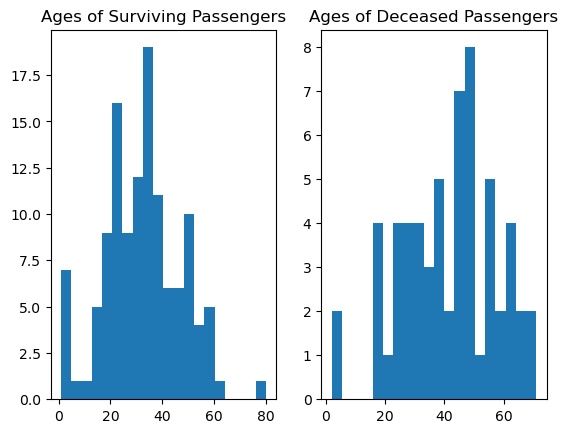

In [85]:
#create histograms for ages of survivng and deceased passengers. Use dropna() to omitt NaN values.
survived = train_data[train_data['Survived'] == 1].dropna()
deceased = train_data[train_data['Survived'] == 0].dropna()
plt.subplot(1, 2, 1)
plt.hist(survived['Age'], bins = 20)
plt.title('Ages of Surviving Passengers')
plt.subplot(1, 2, 2)
plt.hist(deceased['Age'], bins = 20)
plt.title('Ages of Deceased Passengers')

In [86]:
#perform Welch's T-Test
from scipy import stats
t_statistic, p_value = stats.ttest_ind(survived['Age'], deceased['Age'], equal_var = False)
print(f"Welch' T-Test | t_statistic: {t_statistic} | p_value: {p_value}")

Welch' T-Test | t_statistic: -3.4671799996491983 | p_value: 0.0007481344293761371


It appears the number of Siblings and Spouses a passenger had had a negative impact on survival. Those passengers at the extreme end with 5 or 8 siblings or spouses on board did not survive, though when we use value_counts we see that these may account for entire families that decied to stay together.

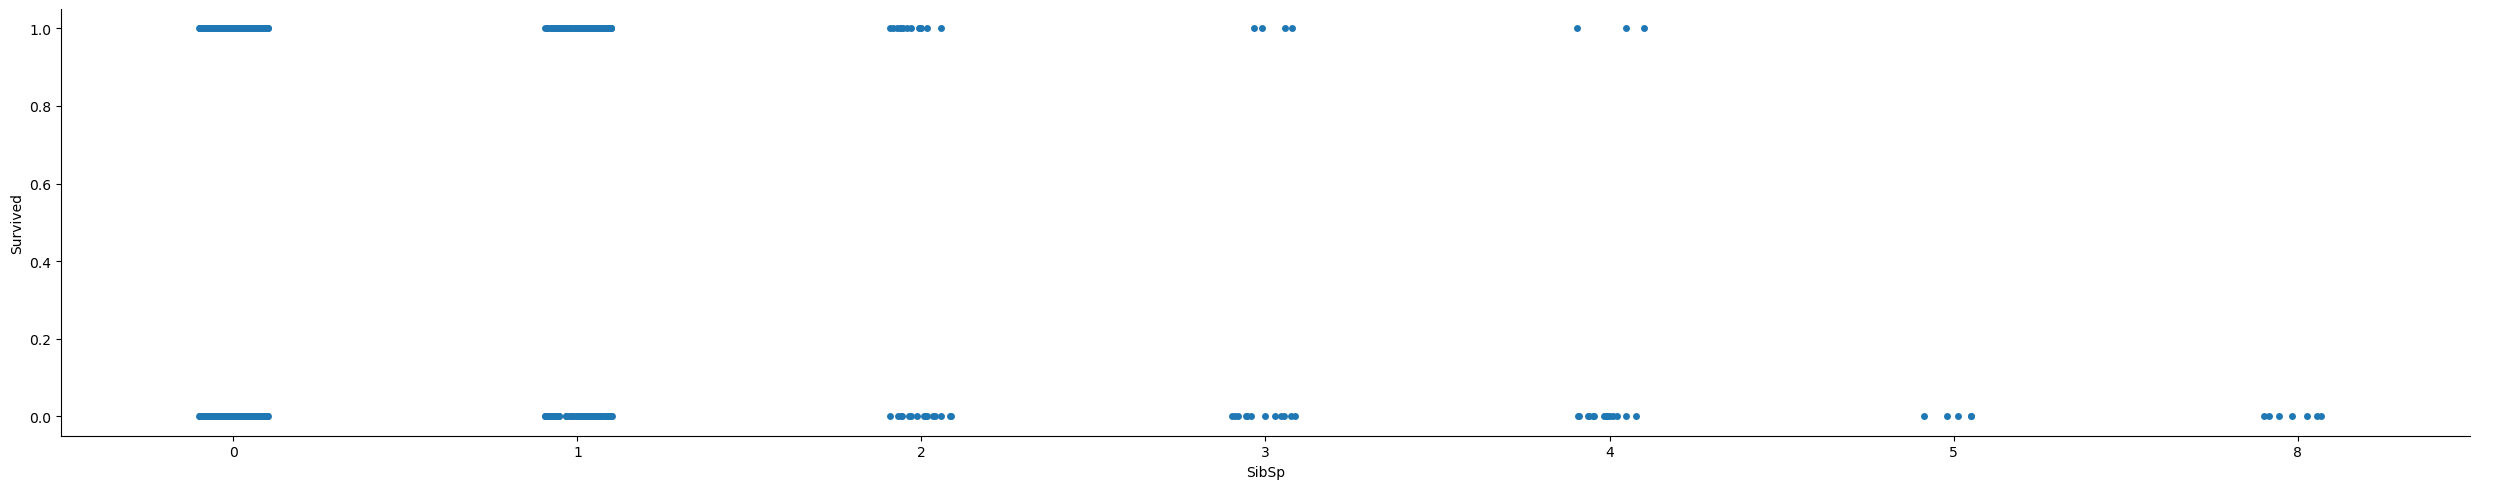

In [14]:
sns.catplot(data = train_data, x = 'SibSp', y = 'Survived', height = 5, aspect = 5)

In [15]:
train_data['SibSp'].value_counts() #count the number of each insteance of the SibSp values

SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

In [16]:
train_data.groupby('Survived')['SibSp'].mean() #group by Survived and average the number of SibSp

Survived
0    0.553734
1    0.473684
Name: SibSp, dtype: float64

The data suggests having more parents or children increased survivability, though at higher values (3 or higher) this trend reverses. 

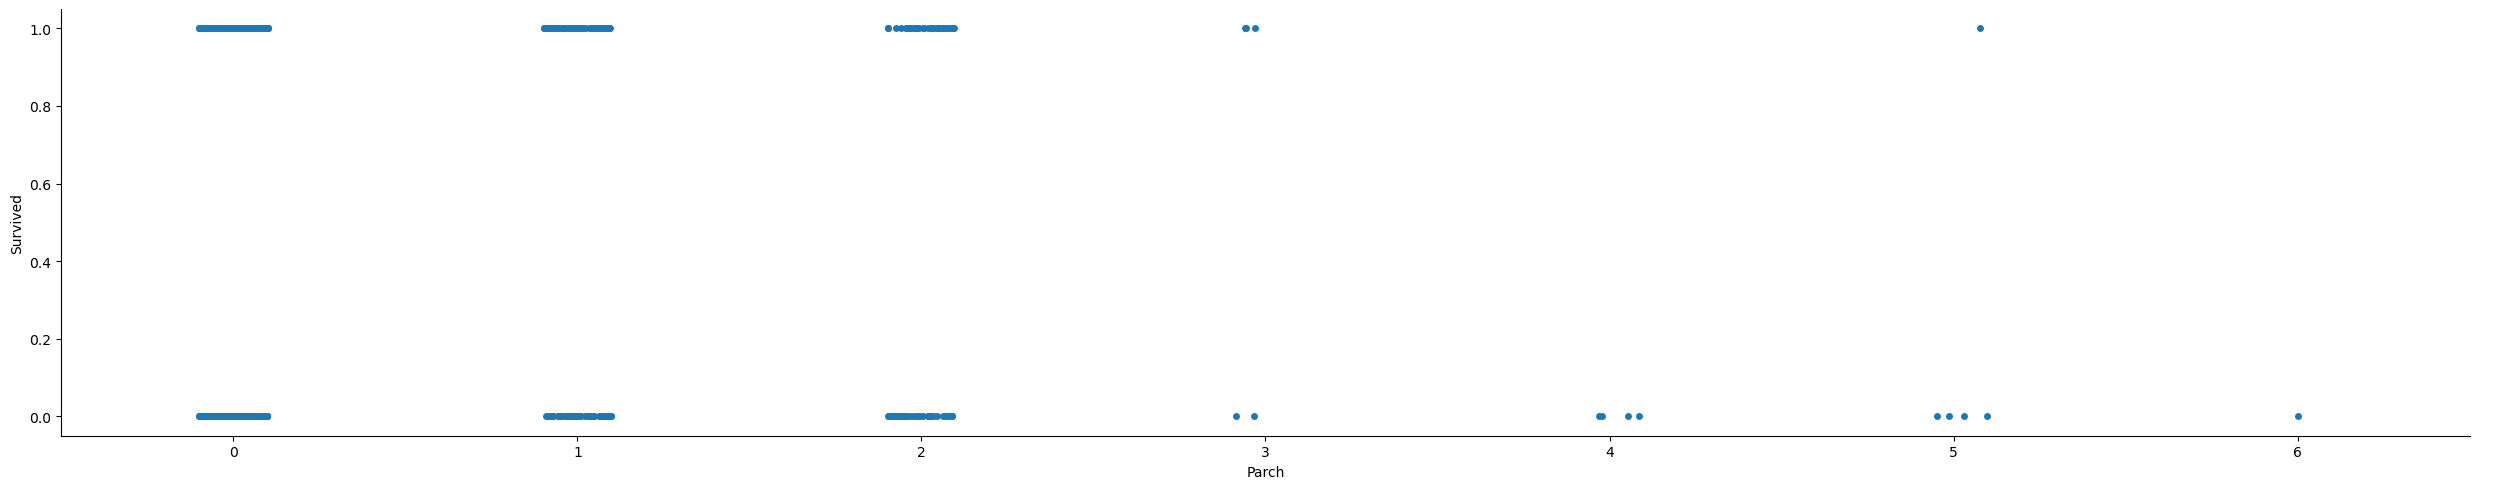

In [17]:
sns.catplot(data = train_data, x = 'Parch', y = 'Survived', height = 5, aspect = 5)

In [18]:
train_data.groupby('Survived')['Parch'].mean() #group by Survived and average the number of Parch

Survived
0    0.329690
1    0.464912
Name: Parch, dtype: float64

Here we use the median to evalute if Fare has an effect on Survival as it is more robust against outliers; some passengers paid exponentially more for their ticktets than their fellows.

<Axes: xlabel='Fare', ylabel='Count'>

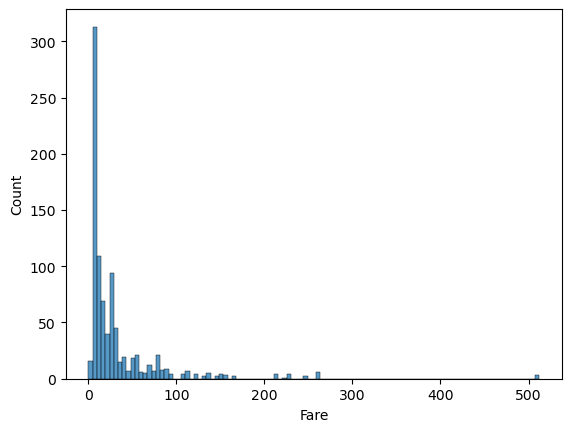

In [19]:
sns.histplot(data = train_data['Fare'])# histogram showing Fare data.

In [20]:
train_data.groupby('Survived')['Fare'].median() # median Fare for the different Survival categories

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64

The survival rate varied more than expected across the three Embarkation locations. Perhaps embarkation point is related somehow to class or fare.

In [21]:
embark_survival = train_data.groupby('Embarked')['Survived'].mean() # groupby Embarked sum Survival
embark_survival

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

<Axes: xlabel='Embarked', ylabel='Survived'>

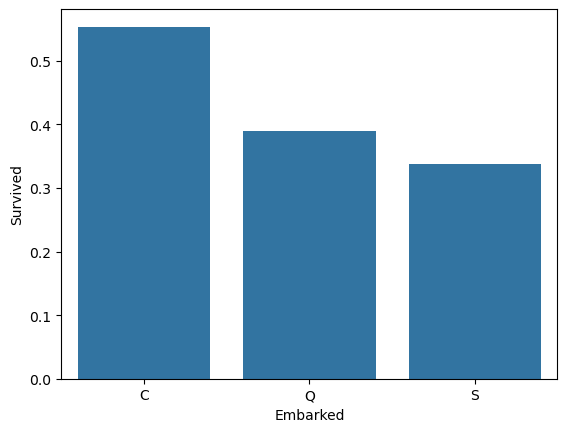

In [22]:
sns.barplot(embark_survival)

In [23]:
train_data.groupby('Embarked')['Pclass'].mean()

Embarked
C    1.886905
Q    2.909091
S    2.350932
Name: Pclass, dtype: float64